In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns
import statsmodels.formula.api as sm

## CLASSWORK

на основании 5 отчетных данный 5 строительных организации получены след результаты Y(Объем) X1(число работников) X2(), матрицу А находим, матрицу F рисуем на плоскости и описывать ..., построить регрессиию по главным компонентам
дз (доделать на +)

In [2]:
df = pd.DataFrame(columns=['X1', 'X2', 'Y'], data=[[3,4,13], [6,5,14], [8,9,16], [2, 8, 12], [7, 6, 15]])

In [3]:
df

,X1,X2,Y
0,3,4,13
1,6,5,14
2,8,9,16
3,2,8,12
4,7,6,15


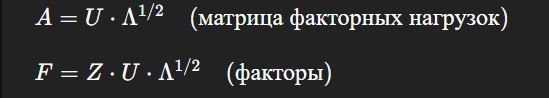

In [4]:
Z = df.drop('Y', axis=1)
Z = Z - Z.mean()
R = (np.transpose(Z) @ Z) / len(df)
eig, eival = np.linalg.eigh(R)

In [5]:
A = eival * np.sqrt(eig)
A

array([[ 0.71462957, -2.20211366],
       [-1.55376236, -1.01282898]])

In [6]:
F = Z @ eival * np.sqrt(eig)
F

,0,1
0,2.156845,7.275440
1,2.746971,-0.343730
2,-2.038819,-8.799274
3,-4.772834,5.426237
4,1.907838,-3.558673


In [7]:
F = F.set_axis(['Component_1', 'Component_2'], axis=1)

In [8]:
F['Y'] = df['Y']
F

,Component_1,Component_2,Y
0,2.156845,7.275440,13
1,2.746971,-0.343730,14
2,-2.038819,-8.799274,16
3,-4.772834,5.426237,12
4,1.907838,-3.558673,15


In [9]:
sm.ols('Y ~ Component_1 + Component_2', F).fit().summary()

C:\Users\Валерий\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\regression\linear_model.py:3158: ValueWarning: omni_normtest is not valid with less than 8 observations; 5 samples were given.
  omni, omnipv = cached("omni_normtest", lambda: omni_normtest(self.wresid))


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      Y   R-squared:                       0.958
Model:                            OLS   Adj. R-squared:                  0.916
Method:                 Least Squares   F-statistic:                     22.76
Date:                Mon, 23 Nov 2026   Prob (F-statistic):             0.0421
Time:                        15:22:31   Log-Likelihood:               -0.90744
No. Observations:                   5   AIC:                             7.815
Df Residuals:                       2   BIC:                             6.643
Df Model:                           2                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      14.0000      0.205     68.243      0.000      13.117      14.883
Component_1     0.1220      0.070      1.740      0.224      -0.180       0.424
Component_2    -0.2276      0.035     -6.519      0.023      -0.378      -0.077
==============================================================================
Omnibus:                          nan   Durbin-Watson:                   3.060
Prob(Omnibus):                    nan   Jarque-Bera (JB):                0.390
Skew:                          -0.011   Prob(JB):                        0.823
Kurtosis:                       1.632   Cond. No.                         5.88
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

In [10]:
pd.concat((F,df.drop('Y', axis=1)), axis=1)

,Component_1,Component_2,Y,X1,X2
0,2.156845,7.275440,13,3,4
1,2.746971,-0.343730,14,6,5
2,-2.038819,-8.799274,16,8,9
3,-4.772834,5.426237,12,2,8
4,1.907838,-3.558673,15,7,6


In [11]:
sm.ols('Y ~ Component_1', F).fit().summary()

C:\Users\Валерий\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\regression\linear_model.py:3158: ValueWarning: omni_normtest is not valid with less than 8 observations; 5 samples were given.
  omni, omnipv = cached("omni_normtest", lambda: omni_normtest(self.wresid))


<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      Y   R-squared:                       0.064
Model:                            OLS   Adj. R-squared:                 -0.248
Method:                 Least Squares   F-statistic:                    0.2040
Date:                Mon, 23 Nov 2026   Prob (F-statistic):              0.682
Time:                        15:22:31   Log-Likelihood:                -8.6631
No. Observations:                   5   AIC:                             21.33
Df Residuals:                       3   BIC:                             20.55
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
===============================================================================
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
Intercept      14.0000      0.790     17.720      0.000      11.486      16.514
Component_1     0.1220      0.270      0.452      0.682      -0.738       0.982
==============================================================================
Omnibus:                          nan   Durbin-Watson:                   2.751
Prob(Omnibus):                    nan   Jarque-Bera (JB):                0.517
Skew:                           0.540   Prob(JB):                        0.772
Kurtosis:                       1.854   Cond. No.                         2.92
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
"""

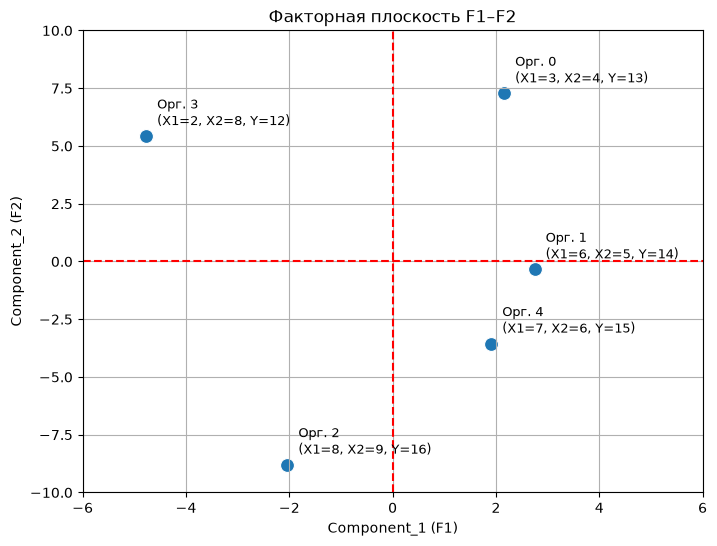

In [12]:
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(x=F['Component_1'], y=F['Component_2'], s=100, ax=ax)

# Подписи точек
for i, row in F.iterrows():
    ax.annotate(f'Орг. {i}\n(X1={df.loc[i,"X1"]}, X2={df.loc[i,"X2"]}, Y={df.loc[i,"Y"]})',
                (row['Component_1'], row['Component_2']),
                textcoords="offset points", xytext=(8, 8), fontsize=9)

plt.axhline(y=0, color='red', linewidth=1.5, linestyle='--')
plt.axvline(x=0, color='red', linewidth=1.5, linestyle='--')

plt.grid(True)
plt.xlim(-6, 6)
plt.ylim(-10, 10)
plt.xlabel('Component_1 (F1)')
plt.ylabel('Component_2 (F2)')
plt.title('Факторная плоскость F1–F2')
plt.show()

In [13]:
from IPython.display import display, Markdown, HTML

# Создаем таблицу квадрантов
quadrant_data = {
    'Квадрант': ['I (F1>0, F2>0)', 'II (F1<0, F2>0)', 'III (F1<0, F2<0)', 'IV (F1>0, F2<0)'],
    'Организации': ['Орг. 0', 'Орг. 3', 'Орг. 2', 'Орг. 1, 4'],
    'Смысл': [
        'Большой размер + высокая удельная з.п.',
        'Малый размер + высокая удельная з.п.',
        'Большой размер + низкая удельная з.п.',
        'Средний/большой размер + умеренная з.п.'
    ]
}

quadrant_df = pd.DataFrame(quadrant_data)

# Отображаем таблицу
print("График разделится на 4 квадранта, и станет наглядно видно:\n")
display(quadrant_df)

# Текстовое описание
description = """
**Это упрощает описание сгущений:**

- **Верхний полукруг (F2>0)** — организации с высокой удельной зарплатой и меньшими объёмами работ

- **Нижний полукруг (F2<0)** — организации с большим числом рабочих и большими объёмами

**Нулевые оси делают это разделение визуально очевидным.**
"""

display(Markdown(description))

График разделится на 4 квадранта, и станет наглядно видно:



,Квадрант,Организации,Смысл
0,"I (F1>0, F2>0)",Орг. 0,Большой размер + высокая удельная з.п.
1,"II (F1<0, F2>0)",Орг. 3,Малый размер + высокая удельная з.п.
2,"III (F1<0, F2<0)",Орг. 2,Большой размер + низкая удельная з.п.
3,"IV (F1>0, F2<0)","Орг. 1, 4",Средний/большой размер + умеренная з.п.



**Это упрощает описание сгущений:**

- **Верхний полукруг (F2>0)** — организации с высокой удельной зарплатой и меньшими объёмами работ

- **Нижний полукруг (F2<0)** — организации с большим числом рабочих и большими объёмами

**Нулевые оси делают это разделение визуально очевидным.**


-----------------------------------------------------------------------------------------------------------

файл магазины.xlsx - дойти до осмысленного описания интегральных факторов, дать адекватное название компонент (python или excel)

учебная задачка:
имеются данные по 5 семьям по двум показателям: X1 - расходы за лето на культуру, спорт и отдых; X2 - расходы за лето на питание (ВСЁ В УСЛОВНЫХ ЕДИНИЦАХ). вначале необходимо нарисовать признаки на плоскости увидеть, что примерно по координатам происходит распределение. находим наименьшее расстояние между соседями, искать расстояние между группами (РАЗОБРАТЬСЯ С РАССТОЯНИЯМИ, ближними и дальними соседями, как выбираются расстояния и так далее). посчитать расстояния через формулу Холмогорова, понять какие обьекты соединять в один кластер. нарисовать на бумаге дендрограмму, ходы решения как на картинках.

In [81]:
df = pd.read_csv('магазины.csv', delimiter=';')

In [82]:
df.dropna(inplace=True)

In [83]:
# Обязательно делим на стандартное отклонение по столбцам!
Z = (Z - Z.mean(axis=0)) / Z.std(axis=0)
R = (Z.T @ Z) / len(Z)

eigens, eigvals = np.linalg.eig(R)
eigens_sorted = np.sort(eigens)[::-1]

In [84]:
# 1. Получаем именно матрицу корреляций (а не ковариаций)
R_corr = np.corrcoef(df, rowvar=False)

# 2. Обратная матрица и матрица частных корреляций
R_inv = np.linalg.inv(R_corr)
D = np.diag(1 / np.sqrt(np.diag(R_inv)))
P = -D @ R_inv @ D  # матрица частных корреляций

# 3. Обнуляем диагонали, чтобы суммировать только парные связи
np.fill_diagonal(R_corr, 0)
np.fill_diagonal(P, 0)

# 4. Считаем общий KMO
kmo_model = np.sum(R_corr**2) / (np.sum(R_corr**2) + np.sum(P**2))
print("Общий KMO:", kmo_model)


Общий KMO: 0.9145592229103002


Число компонент по критерию Кайзера: 6
Собственные значения: [11.227  2.125  1.51   1.252  1.239  1.078  0.997  0.84   0.818  0.75
  0.695  0.693  0.61   0.589  0.54   0.519  0.49   0.458  0.435  0.413
  0.38   0.358  0.335  0.322  0.306  0.283  0.256  0.226  0.171  0.085]
Накопленная дисперсия: [0.374 0.445 0.495 0.537 0.578 0.614 0.648 0.676 0.703 0.728 0.751 0.774
 0.794 0.814 0.832 0.849 0.866 0.881 0.895 0.909 0.922 0.934 0.945 0.956
 0.966 0.975 0.984 0.991 0.997 1.   ]


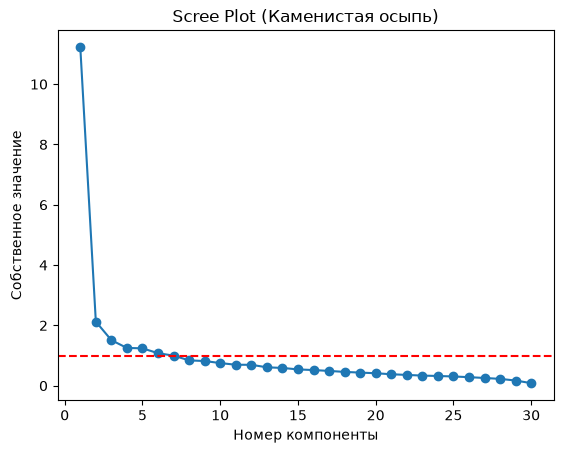

In [85]:
import matplotlib.pyplot as plt
import numpy as np

# Сортируем собственные значения по убыванию (np.linalg.eig не всегда их сортирует)
eigens_sorted = np.sort(eigens)[::-1]

# 1. Критерий Кайзера (сколько значений > 1)
n_kaiser = np.sum(eigens_sorted > 1)
print("Число компонент по критерию Кайзера:", n_kaiser)
print("Собственные значения:", np.round(eigens_sorted, 3))

# 2. Доля объясненной дисперсии (накопленная)
explained_var = np.cumsum(eigens_sorted) / np.sum(eigens_sorted)
print("Накопленная дисперсия:", np.round(explained_var, 3))

# 3. График каменистой осыпи (Scree plot)
plt.plot(range(1, len(eigens_sorted) + 1), eigens_sorted, marker='o')
plt.axhline(y=1, color='r', linestyle='--') # порог Кайзера
plt.title('Scree Plot (Каменистая осыпь)')
plt.xlabel('Номер компоненты')
plt.ylabel('Собственное значение')
plt.show()


In [86]:
# 1. Получаем индексы сортировки по убыванию
idx = np.argsort(eigens)[::-1]
eigens_sorted = eigens[idx]
eigvals_sorted = eigvals[:, idx]

# 2. Берем нужное число компонент (например, k = 6)
k = 6
A = eigvals_sorted[:, :k] * np.sqrt(eigens_sorted[:k])  # матрица факторных нагрузок (30 x 6)
F = (Z @ eigvals_sorted[:, :k]) / np.sqrt(eigens_sorted[:k])                          # новые координаты (главные компоненты)


In [98]:
n = len(Z)

# Считаем стандартизированные факторы F (чтобы выполнилось условие 1)
F = (Z @ eigvals_sorted[:, :k]) / np.sqrt(eigens_sorted[:k])

# --- ПРОВЕРКА УСЛОВИЯ 1: (1/n) * (F.T @ F) == Единичная матрица I ---
cond_1 = (F.T @ F) / n
print("1. Проверка факторов (должна быть единичная матрица I):")
print(np.round(cond_1, 3))

# --- ПРОВЕРКА УСЛОВИЯ 2: (1/n) * (Z.T @ F) == Матрица нагрузок A ---
cond_2 = (Z.T @ F) / n
diff = np.max(np.abs(cond_2 - A))  # максимальная разница между (Z.T @ F)/n и A
print("\n2. Максимальное расхождение между (Z.T @ F)/n и A:", round(diff, 10))

# --- ПРОВЕРКА УСЛОВИЯ 3: Дисперсия столбцов Z равна 1 ---
cond_3 = np.sum(Z**2, axis=0) / n
print("\n3. Дисперсия столбцов Z (все должны быть 1):")
print(np.round(cond_3, 3))


1. Проверка факторов (должна быть единичная матрица I):
[[ 1. -0. -0.  0. -0. -0.]
 [-0.  1.  0.  0.  0. -0.]
 [-0.  0.  1.  0.  0. -0.]
 [ 0.  0.  0.  1. -0.  0.]
 [-0.  0.  0. -0.  1.  0.]
 [-0. -0. -0.  0.  0.  1.]]

2. Максимальное расхождение между (Z.T @ F)/n и A: 0.0

3. Дисперсия столбцов Z (все должны быть 1):
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]


In [99]:
import pandas as pd
import numpy as np

# 1. Функция ортогонального вращения Varimax
def varimax(Phi, gamma=1.0, q=50, tol=1e-6):
    p, k = Phi.shape
    R = np.eye(k)
    d = 0
    for i in range(q):
        d_old = d
        Lambda = np.dot(Phi, R)
        u, s, vh = np.linalg.svd(
            np.dot(Phi.T, np.asarray(Lambda)**3 - (gamma/p) * np.dot(Lambda, np.diag(np.diag(np.dot(Lambda.T, Lambda)))))
        )
        R = np.dot(u, vh)
        d = np.sum(s)
        if d_old != 0 and d / d_old < 1 + tol:
            break
    return np.dot(Phi, R)

# 2. Применяем вращение к вашей матрице нагрузок A (30 x 6)
A_rot = varimax(A)

# 3. Создаем читаемую таблицу с названиями признаков
descriptions = [
    "Кассы для небольшого количества покупок", "Магазин, который интересно посещать",
    "Немедленное обслуживание покупателей", "Компетентный персонал",
    "Хороший выбор компакт-кассет и компакт-дисков", "У магазина чистый и привлекательный вид",
    "Хорошо продуманное расположение товаров", "Повсеместное наличие готовых помочь служащих",
    "Хороший выбор хозяйственных товаров", "Возможность делать покупки для всей семьи",
    "Широкий выбор фирм-производителей", "Наличие информации о номенклатуре товаров на складе",
    "Открыт в удобное время", "Наличие нужных Вам размеров",
    "Цены в среднем ниже, чем в других магазинах", "Можно проверить изделие прямо в магазине",
    "Нет ежегодных платежей", "Служащие магазина способны оказать помощь",
    "Простота процедуры расчета", "Хороший выбор электроники",
    "Наличие на складе высококачественных товаров", "Хороший выбор товаров для праздников",
    "Легко припарковаться около магазина", "Недолго ждать у кассы",
    "Магазин расположен неподалеку", "Дружелюбная обстановка",
    "Просторные проходы", "Принимает все основные кредитные карты",
    "Предлагает специальные торговые скидки", "Скидки хорошо разрекламированны"
]

df_loadings = pd.DataFrame(
    A_rot,
    index=[f"x{i+1}: {desc}" for i, desc in enumerate(descriptions)],
    columns=[f"Фактор {j+1}" for j in range(A_rot.shape[1])]
)

# Выводим только значимые нагрузки (по модулю > 0.5), чтобы было легко читать
print(df_loadings.where(df_loadings.abs() > 0.5, ""))


                                                    Фактор 1  Фактор 2  \
x1: Кассы для небольшого количества покупок                              
x2: Магазин, который интересно посещать                                  
x3: Немедленное обслуживание покупателей           -0.674963             
x4: Компетентный персонал                          -0.735581             
x5: Хороший выбор компакт-кассет и компакт-дисков                        
x6: У магазина чистый и привлекательный вид        -0.509324             
x7: Хорошо продуманное расположение товаров                  -0.534504   
x8: Повсеместное наличие готовых помочь служащих   -0.669617             
x9: Хороший выбор хозяйственных товаров                                  
x10: Возможность делать покупки для всей семьи     -0.512584             
x11: Широкий выбор фирм-производителей                       -0.642732   
x12: Наличие информации о номенклатуре товаров ...           -0.519208   
x13: Открыт в удобное время           